In [1]:
import uproot # for reading .root files

import sys
sys.path.append("../src")
import preselection
from preselection import cut_photon_eta_transition, cut_photon_pt
import features
from features import calc_myy
import plotting
from plotting import plot_data

branches = [
    "photon_n", "trigP", "photon_pt", "photon_eta", "photon_phi", 
    "photon_E", "photon_isTightID", "photon_ptcone30", "photon_etcone20",

    "mcWeight", "scaleFactor_PILEUP", "scaleFactor_PHOTON",
    "scaleFactor_PhotonTRIGGER", "XSection", "SumWeights",

    "jet_n", "jet_pt", "jet_eta", "jet_phi", "jet_jvt"
]

In [2]:
arrays = uproot.open("../data/raw/data_A.GamGam.root:mini").arrays(branches, library="ak")

cutflow = {}
cutflow["all events"] = len(arrays)

arrays = arrays[cut_photon_eta_transition(arrays.photon_eta)]
cutflow["photon eta crack"] = len(arrays)

arrays = arrays[cut_photon_pt(arrays.photon_pt)]
cutflow["photon pT"] = len(arrays)

for name, n in cutflow.items():
    print(f"{name:20s} {n:>10d}  ({n / cutflow['all events']:.1%})")

all events               430344  (100.0%)
photon eta crack         409219  (95.1%)
photon pT                250606  (58.2%)


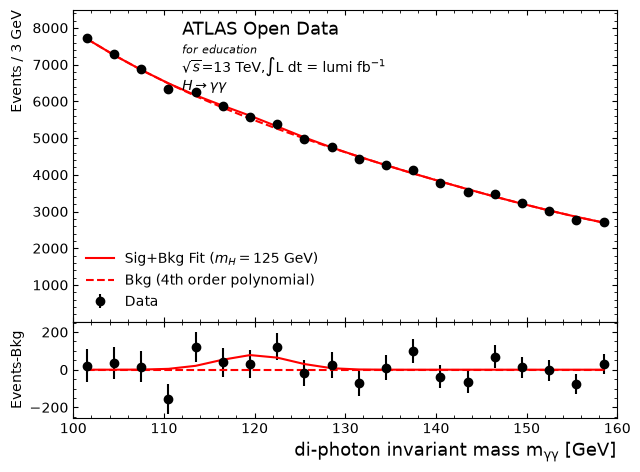

In [3]:
myy = calc_myy(arrays.photon_pt, arrays.photon_eta, arrays.photon_phi, arrays.photon_E)
plot_data(myy)